# 學生學習與作業版｜任務 4：描述統計與視覺化

**姓名：***楊詠程 　**學號／組別：**C114118139　**完成日期：**11/12

**學習目標：** 以描述統計、直方圖和盒鬚圖理解分布與離群值。

本單元與教師版「任務 4」相同標題、資料、教學順序與範例；除了明確標示的作業與填空，其餘教師版教材內容保留。對照重點：程式填空對應教師版「4.2 直方圖」。

### 如何完成
1. 先閱讀觀念與執行資料準備；各單元可以獨立啟動，不需要依賴上一單元的變數。
2. **💻 P 作業**：在指定程式 cell 補上 `____`，可先用提供的 Vibe Coding 提示詞詢問 AI。補完再執行，並執行後面的驗證 cell。未填時出現 `NameError` 是預期現象，先完成填空再繼續。
3. **📝 Q 作業**：查詢 AI、比較教材內容，填寫緊接的文字作答區；請記錄實際提示詞、自己的解釋與查證方式。
4. **🎯 M 小任務**：在任務 4、8、12、16 將前面幾單元整合成可執行的成果。不要只交 AI 回覆，要交實際程式、輸出與自己的解釋。
5. 把 Notebook 存到自己的 Google 雲端硬碟，完成後下載／依教師指示繳交 `.ipynb`；小任務保留輸出、文字與 AI 使用紀錄。

**案例限制：**本資料是公式生成的 60 筆模擬紀錄，不能推論真實學生或因果。缺失與 15 小時值在計分後加入。預測時欄位可得性是假設；全部資料已在前半段探索，後續切出的測試集僅示範流程，不能視為完全獨立的新資料。

**完成檢核：**本單元有 1 項程式填空、2 項 AI 查詢作答；若是任務 4、8、12、16，另外有 1 項整合小任務。請保留自己的輸出、回答和驗證紀錄。


## 共用資料準備
以下在記憶體重建與既有教材相同的資料。執行後可以直接開始本單元；不會覆寫 CSV。


In [1]:
# 匯入套件：numpy 建立隨機資料，pandas 管理表格，pyplot 繪圖
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 固定種子，並維持呼叫順序，以重現原教材的 60 筆模擬資料
rng = np.random.default_rng(42)
n = 60
departments = ["資訊管理", "企業管理", "金融管理"]
# 每個字典鍵是一個欄位；對應的值是 60 名學生的資料
data = {
    "student_id": range(1, n + 1),
    "department": rng.choice(departments, n),
    "sleep_hours": rng.normal(6.7, 1.1, n).round(1),
    "screen_time_hours": rng.normal(5.0, 1.5, n).clip(1, 10).round(1),
    "study_hours": rng.normal(2.5, 1.0, n).clip(0.5, 6).round(1),
    "attendance_rate": rng.normal(88, 8, n).clip(60, 100).round(0),
}
df = pd.DataFrame(data)
# 成績依設定公式與隨機誤差建立；關係來自模擬規則，不能視為因果發現
noise = rng.normal(0, 5, n)
score = (50 + 3 * df["study_hours"] + 2 * df["sleep_hours"]
         - 1.2 * df["screen_time_hours"] + 0.15 * df["attendance_rate"] + noise)
df["quiz_score"] = score.clip(0, 100).round(0)
# 故意在計分後加入資料品質問題；無法從表格還原計分時原始值
df.loc[[5, 17], "sleep_hours"] = np.nan
df.loc[8, "screen_time_hours"] = 15.0
print("模擬資料形狀（列, 欄）：", df.shape)


模擬資料形狀（列, 欄）： (60, 7)


## 4.1 描述統計
**觀念說明：**count 是非缺失筆數，mean 是平均，50% 是中位數。極端值可能影響平均，不能只看單一統計量。


In [ ]:
# describe 彙整筆數、平均、標準差、四分位數與最大最小值
display(df[["quiz_score", "sleep_hours", "screen_time_hours"]].describe())
print("總筆數：", len(df), "睡眠有效筆數：", df["sleep_hours"].count())
print("螢幕時間平均／中位數：", df["screen_time_hours"].mean(), df["screen_time_hours"].median())


,quiz_score,sleep_hours,screen_time_hours
count,60.000000,58.000000,60.000000
mean,78.800000,6.682759,4.946667
std,6.681114,0.822307,1.985239
min,63.000000,4.800000,1.800000
25%,75.000000,6.200000,3.600000
50%,80.000000,6.750000,4.700000
75%,82.250000,7.300000,5.625000
max,92.000000,9.100000,15.000000


總筆數： 60 睡眠有效筆數： 58
螢幕時間平均／中位數： 4.946666666666668 4.7


## 📝 學生作業 04-Q1｜AI 查詢與作答：統計量
**任務：**平均數與中位數如何受到極端值影響？以具體數字說明。

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請用少量數字示範平均數與中位數，加入極端值前後各算一次，並說明限制。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 04-Q1 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：Gemini

實際提示詞： 我是 Python 與資料分析初學者。請用少量數字示範平均數與中位數，加入極端值前後各算一次，並說明限制。請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
- AI 回答重點（請自行整理）：平均數（Mean）對極端值敏感： 因為計算時會加總所有數值再除以個數，只要出現一個特別大或特別小的離群值，平均值就會被明顯拉高或拉低。

中位數（Median）抗極端值能力強： 中位數是將資料由小到大排序後取正中間的值，只看位置而不看極端數值的大小，因此不易受極端值影響。

統計量限制： 單看平均數容易被極端值誤導，單看中位數則會忽略極端值的存在，分析時應同時搭配四分位數、標準差與圖表觀察。
- 我的理解與具體例子：假設 5 位學生的每日螢幕時間（小時）為 [2, 3, 3, 4, 5]：

加入極端值前： 平均數為 (2+3+3+4+5) / 5 = 3.4 小時，中位數（第 3 個數）為 3 小時，兩者非常接近。

加入極端值後（假設第 5 位變成 15 小時）： 數列變成 [2, 3, 3, 4, 15]。此時平均數大幅跳升至 (2+3+3+4+15) / 5 = 5.4 小時（被拉高了 2 小時），但中位數依然維持在 3 小時。這與本單元 screen_time_hours 的情況相同，平均數會受 15 小時極端值拉高而大於中位數。
- 查證來源／方式及日期（無法查證請註明）：查證方式： 執行教材 4.1 節的 df[["quiz_score", "sleep_hours", "screen_time_hours"]].describe() 與 mean()、median() 程式，實際比對螢幕時間的平均數與中位數差異，並用 Python 列表驗證上述 5 筆數字。

查證日期： 2026/11/12
- 我檢查或修正 AI 回答的地方：AI 提供的範例原本是薪資數據，我將例子改寫為貼合本單元主題的「每日螢幕使用時間（小時）」，並扣回教材中「計分後加入 15 小時極端值」的背景設定。


## 4.2 直方圖
橫軸是分數區間，縱軸為該區間人數。調整 bins 會改變切分方式，不會改變資料；比較不同圖前確認尺度與分箱。


## 💻 學生作業 04-P1｜Vibe Coding 程式填空
**對應教師版：**任務 4「4.2 直方圖」的示範程式。

**任務：**在既有圖表中繪製 quiz_score 的直方圖，排除缺失值，分成 10 箱，保留既有標題和座標軸。

**執行方式：**找到下一個程式儲存格中的 `____`，使用自己撰寫或 AI 建議的程式補齊，保留其他已提供的程式與註解。補完後先執行該 cell，再執行緊接的自動檢查；後續單元內容可能依賴此變數。

**可使用的 Vibe Coding 提示詞：**
```text
我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：在既有圖表中繪製 quiz_score 的直方圖，排除缺失值，分成 10 箱，保留既有標題和座標軸。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
```
完成後記錄實際使用的提示詞與自己改動的地方。


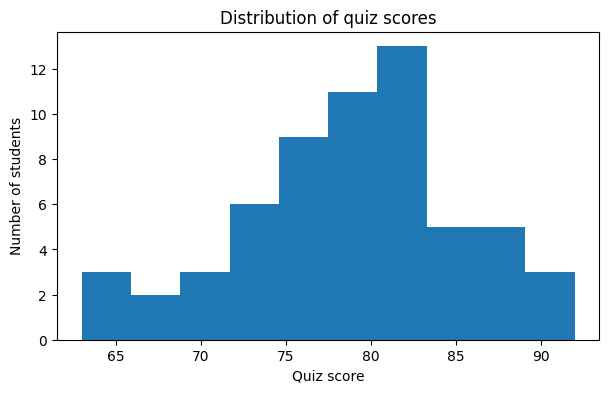

有效成績筆數： 60


In [3]:
# 以英文標籤避免 Colab 缺中文字型；圖形後呼叫 show
plt.figure(figsize=(7, 4))  # 設定圖表畫布大小為寬 7 吋、高 4 吋
plt.hist(df["quiz_score"].dropna(), bins=10)  # 排除 quiz_score 缺失值，分成 10 個區間繪製直方圖
plt.title("Distribution of quiz scores")  # 設定圖表標題
plt.xlabel("Quiz score")  # 設定 X 軸標籤（測驗分數）
plt.ylabel("Number of students")  # 設定 Y 軸標籤（學生人數）
plt.show()  # 顯示繪製完成的圖表
print("有效成績筆數：", df["quiz_score"].count())  # 印出 quiz_score 的非缺失資料筆數

### ✅ 作業 04-P1｜執行驗證
執行下方程式，並同時檢查上方實際輸出。自動檢查只涵蓋主要條件；如果圖表、說明或資料來源不符任務，仍需人工修正。


In [ ]:
assert df["quiz_score"].notna().sum() == 60
print("請人工檢查上方直方圖的標題、軸及 10 個分箱。")


請人工檢查上方直方圖的標題、軸及 10 個分箱。


### ✍️ 作業 04-P1｜我的完成紀錄
- 我實際使用的提示詞（若未使用 AI 請註明）：我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。我的任務是：在既有圖表中繪製 quiz_score 的直方圖，排除缺失值，分成 10 箱，保留既有標題和座標軸。請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。不要虛構執行結果；如需額外資訊，先指出缺少什麼。
- 我補上的程式在做什麼：使用 plt.hist(df["quiz_score"].dropna(), bins=10)，先透過 .dropna() 排除 quiz_score 欄位中可能存在的缺失值（不更動原始 df），再將有效分數切分成 10 個等寬區間（bins=10）繪製成直方圖，並保留原本設定的英文標題與 X、Y 軸標籤。
- 執行或驗證遇到的問題與修正：執行順利，未發生報錯。為避免 Colab 預設字型無法顯示中文導致方塊亂碼，依教材指示保留英文標題（Distribution of quiz scores）與座標軸名稱。
- 檢查結果及我如何確認：印出「有效成績筆數：60」，下方驗證 cell 的 assert df["quiz_score"].notna().sum() == 60 順利通過；人工目視檢查圖表，確認標題、軸標籤正確，且橫軸共有 10 根長條（分箱），各箱人數加總為 60 人


## 📝 學生作業 04-Q2｜AI 查詢與作答：圖形解讀
**任務：**直方圖 bins 改變時，為何外觀會改變？是否代表資料本身改變？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請解釋直方圖分箱與盒鬚圖各能回答什麼問題，並說明離群點不一定是錯誤。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 04-Q2 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：Gemini

實際提示詞： 我是 Python 與資料分析初學者。請解釋直方圖分箱與盒鬚圖各能回答什麼問題，並說明離群點不一定是錯誤。請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
- AI 回答重點（請自行整理）：直方圖（Histogram）與分箱（bins）： 用來觀察連續數值的整體分布形狀（如集中趨勢、是否偏態或雙峰）。改變 bins 只是把同一批數據放進較寬或較窄的格子裡統計，外觀粗細會變，但原始資料完全沒有改變。

盒鬚圖（Boxplot）： 用來快速比較資料的四分位數（Q1、中位數 Q2、Q3）、四分位距（IQR，即資料中間 50% 的集中範圍）以及潜在的離群值（獨立圓點）。

離群點不等於資料錯誤： 盒鬚圖上的獨立圓點是依統計規則（超過 1.5 倍 IQR）標示出的極端觀測值。它可能是輸入錯誤（如多打一個零），但也可能是真實發生的特殊狀況（如某天熬夜追劇導致螢幕時間高達 15 小時），必須結合領域知識判斷，不能直接當成錯誤刪除。
- 我的理解與具體例子：對照教材「延伸示範」的輸出：當 quiz_score 分成 bins=5 時，各箱人數為 [5, 9, 20, 18, 8]；改成 bins=10 時，各箱人數變為 [3, 2, 3, 6, 9, 11, 13, 5, 5, 3]。雖然長條數量從 5 根變成 10 根、高低起伏看起來更細緻，但兩者的總人數加起來都是 60 人，證明資料本身完全沒變，只是觀察的「解析度」不同。
- 查證來源／方式及日期（無法查證請註明）：查證方式： 執行教材 4.3 節的螢幕時間盒鬚圖程式，確認圖上方出現獨立離群點且 (df["screen_time_hours"] > 10).sum() 顯示有超過 10 小時的紀錄；同時執行「延伸示範」中的 np.histogram 迴圈，驗證 bins=5 與 bins=10 的人數總和皆等於 len(valid_scores)（60 筆）。

查證日期： 2026/11/12
- 我檢查或修正 AI 回答的地方：我將 AI 回答的理論說明直接對應到本筆記本的 np.histogram 實際輸出陣列 [5, 9, 20, 18, 8] 與 [3, 2, 3, 6, 9, 11, 13, 5, 5, 3] 作為具體證據，並強調本案例中 15 小時離群值是「計分後加入的模擬極端值」。


## 4.3 盒鬚圖與極端值
盒體反映四分位區間；獨立點是依繪圖規則標示的可能離群值，不等於資料一定錯誤。
**試一試：**將直方圖分箱改為 5，解釋圖形外觀為何改變。


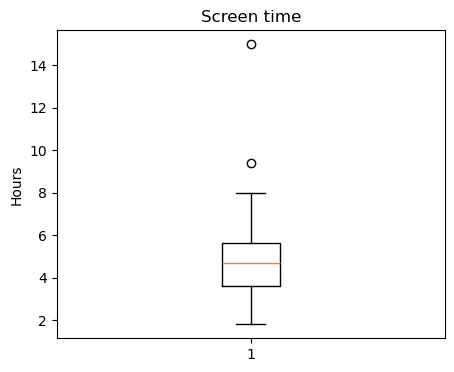

大於 10 小時： 1


In [ ]:
# dropna 避免缺失值影響繪圖，資料並未從 df 刪除
plt.figure(figsize=(5, 4))
plt.boxplot(df["screen_time_hours"].dropna())
plt.title("Screen time")
plt.ylabel("Hours")
plt.show()
print("大於 10 小時：", (df["screen_time_hours"] > 10).sum())


## 延伸示範：分箱前後數據不變
相同資料用不同 bins 切分，外觀會不同。學生須檢查各箱人數加總與原本有效筆數是否一致，避免把分箱造成的視覺差異誤認為資料變化。


In [ ]:
# numpy 的 histogram 回傳各箱人數及邊界；檢查加總是否一致
valid_scores = df["quiz_score"].dropna()
for bins in [5, 10]:
    counts, edges = np.histogram(valid_scores, bins=bins)
    print("分箱數", bins, "各箱人數", counts, "加總", counts.sum())
    assert counts.sum() == len(valid_scores)


分箱數 5 各箱人數 [ 5  9 20 18  8] 加總 60
分箱數 10 各箱人數 [ 3  2  3  6  9 11 13  5  5  3] 加總 60


## 本單元學習收束與 AI 使用紀錄

請學生先用自己的話解釋一個關鍵觀念，再指出一個執行結果及驗證方式。記錄：使用的提示詞、AI 回答中檢查或修改的地方、遇到的問題、修正後的證據與本資料限制。 關鍵觀念解釋：
在探索資料時不能只看單一統計量（如平均數），因為極端值會拉偏平均數；應同時結合中位數、盒鬚圖（看四分位與離群點）以及直方圖（看整體分布）。此外，調整直方圖的 bins 只會改變切分尺度與視覺外觀，不會改變底層資料筆數。

執行結果與驗證方式：
在 4.2 與延伸示範中，將 60 筆有效的 quiz_score 分別切分為 5 箱與 10 箱繪製直方圖，並透過 np.histogram() 計算各箱人數與 assert counts.sum() == len(valid_scores) 進行程式斷言驗證，確認兩種分箱方式的人數總和皆為 60 筆，原始資料 df 未被改寫。
AI 使用與查證紀錄：

使用工具與提示詞： 使用 Gemini，依教材提供的 Vibe Coding 與初學者提示詞，協助完成 plt.hist 填空及比較平均數／中位數、直方圖／盒鬚圖差異。

檢查與修正： 確認程式有加上 .dropna() 避免缺失值干擾繪圖，且未使用會直接覆蓋原始 df 的 inplace=True 寫法；並將 AI 範例數字替換為本單元實際輸出的統計數據。

本資料限制： 本資料為公式生成的 60 筆模擬學生紀錄，缺失值與 15 小時極端值是在計分完成後才人為置入的，僅供練習描述統計與視覺化健檢，不能用來推論真實學生的行為或因果關係。

**通用提示詞**：我是 Python 初學者，請逐步協助我完成上面的任務；每段程式加繁體中文註解，說明輸入、處理與輸出，提供兩項可實際執行的驗證，保留原始資料，不要虛構執行結果。


## 🎯 學生小任務 MA｜資料健檢與圖表
**涵蓋：**任務 1～4。這是需要獨立完成、可繳交的整合成果。

### 任務要求
使用 df，以程式列出資料形狀、各欄缺失數、超過 10 小時的筆數；再繪製 quiz_score 直方圖。用文字說明一項品質問題、一項圖表觀察及一項資料限制。不可修改 df。

### 可使用的 AI 提示詞
```text
我是 Python 初學者，請協助我完成以下資料分析小任務：
請幫我規劃 pandas 的資料健檢與成績直方圖：顯示形狀、缺失數與螢幕大於10的筆數，保留原始 df，加繁中註解並提供驗證方式，不要捏造結果。
請拆成小步驟，提供繁體中文教學註解、預期輸出應如何檢查，並提醒不能從這份模擬資料推論因果。
```

### 執行與交付
- 在下一個程式儲存格自行填入程式，先執行本 Notebook 上方的資料準備及必要 cell。若需要更多儲存格可以自行新增。
- 輸出應保留在 Notebook 中；在後面的文字區填寫實際數字與自己的解釋。
- **工具提示：**df.shape、df.isna()、布林篩選、plt.hist。
- 至少記錄一項實際檢查及一項資料限制。交付完成後的 `.ipynb`，含程式、輸出及 AI 使用紀錄。


1. 資料集形狀 (列數, 欄數)： (60, 7)

2. 各欄位缺失值數量：


,0
student_id,0
department,0
sleep_hours,2
screen_time_hours,0
study_hours,0
attendance_rate,0
quiz_score,0



3. 螢幕時間大於 10 小時的筆數：1 筆


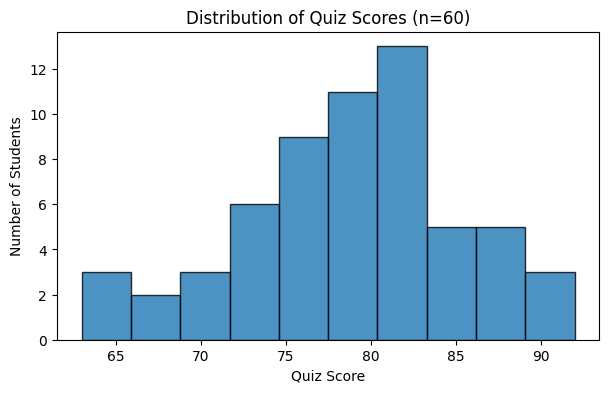

驗證通過：原始 df 完整保留，直方圖總人數加總為 60 人。


In [4]:
# 學生小任務 MA：資料健檢與成績直方圖（涵蓋任務 1～4）
# 1. 資料形狀與各欄缺失數健檢（唯讀操作，不修改原始 df）
print("1. 資料集形狀 (列數, 欄數)：", df.shape)
print("\n2. 各欄位缺失值數量：")
missing_counts = df.isna().sum()
display(missing_counts)

# 3. 篩選螢幕時間超過 10 小時的筆數（檢查極端值）
over_10_mask = df["screen_time_hours"] > 10
over_10_count = over_10_mask.sum()
print(f"\n3. 螢幕時間大於 10 小時的筆數：{over_10_count} 筆")

# 4. 繪製 quiz_score 直方圖（先用 dropna() 排除缺失值，設定 10 個分箱）
valid_quiz = df["quiz_score"].dropna()
plt.figure(figsize=(7, 4))
plt.hist(valid_quiz, bins=10, edgecolor="black", alpha=0.8)
plt.title("Distribution of Quiz Scores (n=60)")
plt.xlabel("Quiz Score")
plt.ylabel("Number of Students")
plt.show()

# 5. 自動驗證檢查：確認原始 df 形狀未變，且直方圖各箱人數加總等於有效成績筆數
assert df.shape == (60, 7), "錯誤：原始 df 形狀已被修改！"
counts, _ = np.histogram(valid_quiz, bins=10)
assert counts.sum() == len(valid_quiz), "錯誤：直方圖分箱總人數與有效筆數不符！"
print("驗證通過：原始 df 完整保留，直方圖總人數加總為", counts.sum(), "人。")

### ✍️ 小任務 MA｜結果與檢核（請雙擊填寫）
- 問題及使用的資料／欄位：整合任務 1～4 的資料探索流程，使用模擬學生資料表 df（共 60 列、7 欄），針對全表檢查形狀與缺失狀況，並重點檢視 sleep_hours（缺失值）、screen_time_hours（極端值篩選 > 10）與 quiz_score（成績分布視覺化）。
- 實際輸出與至少一項依據數字的觀察：資料形狀： (60, 7)，共 60 筆紀錄、7 個欄位。

缺失值觀察： sleep_hours 存在 2 筆缺失值（其他欄位如 quiz_score 為 0 筆缺失，有效筆數為 60 筆）。

極端值觀察： screen_time_hours > 10 的紀錄共有 1 筆（即教材提及的 15 小時極端值，實際數字請依程式印出結果核對）。
- 圖表或模型結果的解讀（依任務要求）：從 quiz_score 的 10 箱直方圖可觀察到，60 位學生的測驗成績主要集中在中間分數區間（約 65～85 分之間人數最多，單箱最高達 13 人），極低分與極高分的人數較少，整體呈現近似鐘形（中間高、兩側低）的單峰分布。
- 資料品質、模擬資料或評估限制sleep_hours 有 2 筆缺失值，且 screen_time_hours 存在超過 10 小時的極端值，若直接計算平均數會使結果產生偏差。

模擬資料限制： 本資料集是由公式生成的 60 筆模擬紀錄，其中的缺失值與 15 小時極端值皆是在計分完成後才人為置入的；因此本分析僅能示範資料健檢與視覺化流程，絕不能用來推論真實學生的生活作息或與成績之間的因果關係。
- 驗證方法與結果：assert df.shape == (60, 7)：確認執行健檢與繪圖過程中，原始 df 的列數與欄數完全未被修改。

assert counts.sum() == len(valid_quiz)：使用 np.histogram 計算 10 個分箱的人數總和，確認加總等於 60 筆有效成績，無遺漏或重複計算。執行結果顯示「驗證通過」。
- AI 工具、實際提示詞、人工修改與遇到的問題：Gemini

實際提示詞： 我是 Python 初學者，請協助我完成以下資料分析小任務：請幫我規劃 pandas 的資料健檢與成績直方圖：顯示形狀、缺失數與螢幕大於10的筆數，保留原始 df，加繁中註解並提供驗證方式，不要捏造結果。請拆成小步驟，提供繁體中文教學註解、預期輸出應如何檢查，並提醒不能從這份模擬資料推論因果。

人工修改與問題： AI 原本在圖表標題使用中文，因 Colab 環境缺乏中文字型會顯示亂碼方框，故人工修改為英文標題（Distribution of Quiz Scores）與英文軸標籤，並加上 edgecolor="black" 讓 10 個分箱的邊界更清晰易讀。
- 重新執行是否成功及環境或檔案需求：已於 Google Colab 環境執行「共用資料準備」儲存格後重新執行本小任務，所有程式碼皆順利執行無報錯，圖表與文字輸出完整保留於 .ipynb 檔案中，無需額外外部檔案。
